# 01 — Model `return-risk`: kết quả huấn luyện trên AWS

Đọc lại run MLflow `mysterious-flea-253` (pipeline Kubeflow `return_risk_training` trên EKS) từ file bằng chứng đã commit
[`mlflow-model-lineage.json`](../docs/evidence/aws/mlflow-model-lineage.json), rồi trả lời hai câu hỏi:
model thắng baseline bao nhiêu, và dữ liệu nào đã sinh ra model này.

Notebook chỉ đọc file trong repo, không cần kết nối AWS. Chạy: `uv run --with jupyter --with matplotlib --with pandas jupyter nbconvert --execute --inplace notebooks/01_model_training_evidence.ipynb`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
lineage = json.loads((EVIDENCE / "aws" / "mlflow-model-lineage.json").read_text())
m, params, tags = lineage["metrics"], lineage["params"], lineage["tags"]
print("model :", lineage["model"]["name"], "v" + lineage["model"]["version"])
print("run   :", lineage["run_name"], lineage["run_id"])
print("thuật toán:", params["algo"], "| seed:", params["seed"])
print("đặc trưng :", *params["features"].split(","), sep="\n  - ")

model : return-risk v1
run   : mysterious-flea-253 adba2b9f197e4e60a141acaf19682a61
thuật toán: lightgbm | seed: 7
đặc trưng :
  - channel
  - country
  - ordered_basis_qty
  - ordered_product_net_minor
  - unit_price_minor
  - labeled_count_90d
  - return_or_refund_rate_90d
  - approved_returns_24h


## Model so với baseline

Baseline là tỷ lệ trả hàng 90 ngày của SKU (không học gì). Chỉ số là PR-AUC (average precision) trên **cùng** tập test, vì nhãn mất cân bằng
(khoảng 11% là trả/hoàn), nên mốc "đoán ngẫu nhiên" chính là tỷ lệ dương `prevalence`.

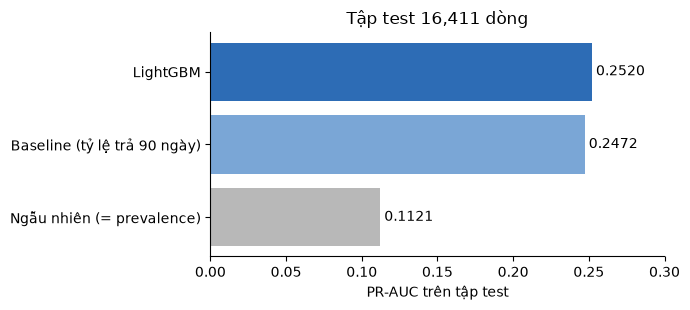

In [3]:
rows = {"Ngẫu nhiên (= prevalence)": m["prevalence"], "Baseline (tỷ lệ trả 90 ngày)": m["pr_auc_baseline"], "LightGBM": m["pr_auc_model"]}
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(list(rows), list(rows.values()), color=["#b8b8b8", "#7aa6d6", "#2d6cb5"])
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_xlim(0, 0.3)
ax.set_xlabel("PR-AUC trên tập test")
ax.set_title(f"Tập test {int(m['test_rows']):,} dòng")
plt.tight_layout()
plt.show()

In [4]:
gap = m["pr_auc_model"] - m["pr_auc_baseline"]
print(f"lift so với ngẫu nhiên : {m['pr_auc_model'] / m['prevalence']:.2f}x (MLflow ghi {m['lift_model']:.2f}x)")
print(f"hơn baseline           : {gap:+.4f} PR-AUC = {gap / m['pr_auc_baseline']:+.1%} tương đối")
assert abs(m["pr_auc_model"] / m["prevalence"] - m["lift_model"]) < 1e-9, "lift trong MLflow lệch so với tính lại"
assert m["beats_baseline"] == 1.0

lift so với ngẫu nhiên : 2.25x (MLflow ghi 2.25x)
hơn baseline           : +0.0048 PR-AUC = +1.9% tương đối


**Đọc kết quả.** Model hơn ngẫu nhiên hơn hai lần (lift 2,25), nhưng chỉ hơn baseline khoảng 0,005 PR-AUC (~2% tương đối).
Đây là **một run, một seed, không có khoảng tin cậy**, nên đủ để pipeline đặt `production` theo luật "thắng baseline" nhưng không đủ để khẳng định
model tốt hơn rule đơn giản một cách có ý nghĩa thống kê. Phần kiểm tra bằng bootstrap và nhiều seed nằm ở [notebook 05](05_retrain_and_bootstrap.ipynb): khoảng tin cậy 95% của chênh lệch là `[-0,0003; +0,0099]`, chạm 0.

## Dữ liệu sinh ra model này

Các tag `data.*` do bước `register` ghi vào run: đường dẫn nguồn, lần sinh dữ liệu và SHA-256 của train/test. Script
[`mlflow_run_data_proof.py`](../scripts/evidence/mlflow_run_data_proof.py) đã đối chiếu SHA-256 của artifact `data/train`, `data/test` với các tag này (khớp).

In [5]:
pd.Series(tags, name="giá trị").to_frame()

,giá trị
data.dataset_version,order_snapshots
data.entity_path,s3://platform-665116832975-lakehouse/feature-s...
data.generation_id,manual__2026-10-28T16:18:15.667507+00:00
data.test_sha256,963a7b8bfd52fa50ac15aa1b95b772a06cfb2204a419fa...
data.train_sha256,eb155450ca577fca53e9a6a86c21e284763f4dbc9c68b4...
